# Random Forest
dataset: Body Performance Data (kaggle)

predicting the fitness class (A, B, C, D) of a person using random forest. A is the best and D is the worst

i used the same data as the logistic regression assignment but this time with all 4 classes not binary

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

## Load the data

In [2]:
df = pd.read_csv('/kaggle/input/datasets/kukuroo3/body-performance-data/bodyPerformance.csv')
df.head()

,age,gender,height_cm,weight_kg,body fat_%,diastolic,systolic,gripForce,sit and bend forward_cm,sit-ups counts,broad jump_cm,class
0,27.0,M,172.3,75.24,21.3,80.0,130.0,54.9,18.4,60.0,217.0,C
1,25.0,M,165.0,55.80,15.7,77.0,126.0,36.4,16.3,53.0,229.0,A
2,31.0,M,179.6,78.00,20.1,92.0,152.0,44.8,12.0,49.0,181.0,C
3,32.0,M,174.5,71.10,18.4,76.0,147.0,41.4,15.2,53.0,219.0,B
4,28.0,M,173.8,67.70,17.1,70.0,127.0,43.5,27.1,45.0,217.0,B


In [3]:
print(df.shape)
print(df.isnull().sum().sum())   # no missing values
print(df.duplicated().sum())     # 1 duplicate

(13393, 12)
0
1


In [4]:
df['class'].value_counts()

class
C    3349
D    3349
A    3348
B    3347
Name: count, dtype: int64

the 4 classes are almost the same size so its balanced

In [5]:
df.describe()

,age,height_cm,weight_kg,body fat_%,diastolic,systolic,gripForce,sit and bend forward_cm,sit-ups counts,broad jump_cm
count,13393.000000,13393.000000,13393.000000,13393.000000,13393.000000,13393.000000,13393.000000,13393.000000,13393.000000,13393.000000
mean,36.775106,168.559807,67.447316,23.240165,78.796842,130.234817,36.963877,15.209268,39.771224,190.129627
std,13.625639,8.426583,11.949666,7.256844,10.742033,14.713954,10.624864,8.456677,14.276698,39.868000
min,21.000000,125.000000,26.300000,3.000000,0.000000,0.000000,0.000000,-25.000000,0.000000,0.000000
25%,25.000000,162.400000,58.200000,18.000000,71.000000,120.000000,27.500000,10.900000,30.000000,162.000000
50%,32.000000,169.200000,67.400000,22.800000,79.000000,130.000000,37.900000,16.200000,41.000000,193.000000
75%,48.000000,174.800000,75.300000,28.000000,86.000000,141.000000,45.200000,20.700000,50.000000,221.000000
max,64.000000,193.800000,138.100000,78.400000,156.200000,201.000000,70.500000,213.000000,80.000000,303.000000


some values look wrong, like diastolic and systolic = 0 and gripForce = 0, and the max of sit and bend forward is 213 cm which is impossible. so i will remove these rows

## Preprocessing
- remove the duplicate
- remove the wrong values
- change gender to numbers (M = 1, F = 0)

i didnt use scaling because random forest doesnt need it

In [6]:
df = df.drop_duplicates()

df = df[df['diastolic'] >= 40]
df = df[df['systolic'] >= 70]
df = df[df['gripForce'] > 0]
df = df[df['broad jump_cm'] > 0]
df = df[df['sit and bend forward_cm'] <= 60]

df['gender'] = df['gender'].map({'M': 1, 'F': 0})

print(df.shape)

(13370, 12)


In [7]:
X = df.drop('class', axis=1)
y = df['class']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(X_train.shape, X_test.shape)

(10696, 11) (2674, 11)


## Random Forest (default)
first i tried it with the default values

In [8]:
model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print('train accuracy:', accuracy_score(y_train, model.predict(X_train)))
print('test accuracy :', accuracy_score(y_test, y_pred))

train accuracy: 1.0
test accuracy : 0.7243829468960359


train accuracy is 1 and test is lower so its overfitting. i think its because max_depth is None by default so the trees keep growing

## Gini vs Entropy

In [9]:
for c in ['gini', 'entropy']:
    start = time.time()
    m = RandomForestClassifier(criterion=c, random_state=42)
    m.fit(X_train, y_train)
    end = time.time()
    print(c, '-> accuracy:', round(accuracy_score(y_test, m.predict(X_test)), 4), ' time:', round(end - start, 2), 's')

gini -> accuracy: 0.7244  time: 2.92 s
entropy -> accuracy: 0.7315  time: 3.43 s


almost the same accuracy, entropy was a little better but gini is faster

## Trying different max_depth

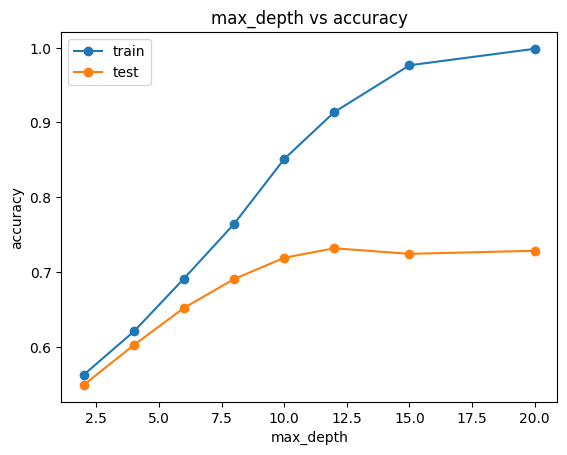

In [10]:
depths = [2, 4, 6, 8, 10, 12, 15, 20]
train_acc = []
test_acc = []

for d in depths:
    m = RandomForestClassifier(max_depth=d, random_state=42)
    m.fit(X_train, y_train)
    train_acc.append(accuracy_score(y_train, m.predict(X_train)))
    test_acc.append(accuracy_score(y_test, m.predict(X_test)))

plt.plot(depths, train_acc, marker='o', label='train')
plt.plot(depths, test_acc, marker='o', label='test')
plt.xlabel('max_depth')
plt.ylabel('accuracy')
plt.legend()
plt.title('max_depth vs accuracy')
plt.show()

after depth 12 the test accuracy doesnt really go up anymore but train keeps going up, so deeper trees just overfit

## Hyperparameter tuning
using GridSearchCV to find the best values

In [11]:
params = {
    'n_estimators': [100, 200],
    'max_depth': [10, 15, 20],
    'max_features': ['sqrt', 'log2'],
    'min_samples_split': [2, 5]
}

grid = GridSearchCV(RandomForestClassifier(random_state=42), params, cv=3)
grid.fit(X_train, y_train)

print(grid.best_params_)
print(grid.best_score_)

{'max_depth': 20, 'max_features': 'sqrt', 'min_samples_split': 2, 'n_estimators': 200}
0.7316747936526915


## Final model

In [12]:
best_model = grid.best_estimator_
y_pred = best_model.predict(X_test)

print('Accuracy :', round(accuracy_score(y_test, y_pred), 4))
print('Precision:', round(precision_score(y_test, y_pred, average='macro'), 4))
print('Recall   :', round(recall_score(y_test, y_pred, average='macro'), 4))
print('F1       :', round(f1_score(y_test, y_pred, average='macro'), 4))

Accuracy : 0.7337
Precision: 0.7387
Recall   : 0.735
F1       : 0.7335


i used average='macro' because there are 4 classes

In [13]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           A       0.70      0.87      0.78       638
           B       0.60      0.59      0.60       661
           C       0.73      0.67      0.70       691
           D       0.92      0.81      0.86       684

    accuracy                           0.73      2674
   macro avg       0.74      0.73      0.73      2674
weighted avg       0.74      0.73      0.73      2674



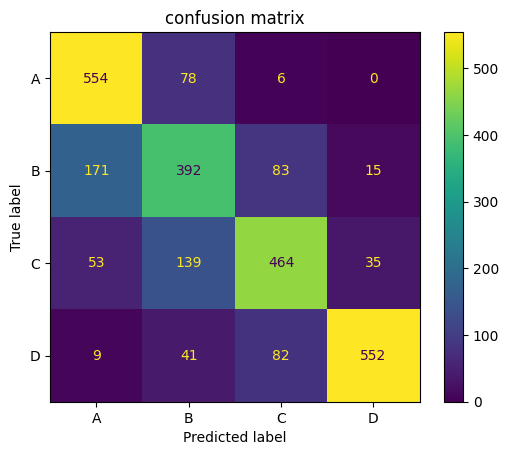

In [14]:
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=best_model.classes_).plot()
plt.title('confusion matrix')
plt.show()

class A and D are the easiest. most of the mistakes are with the class next to it, like B gets predicted as A or C. it almost never mixes A and D

## Feature importance

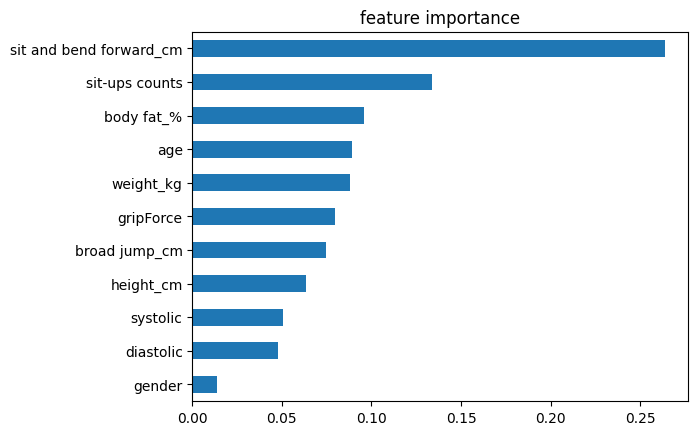

In [15]:
importance = pd.Series(best_model.feature_importances_, index=X.columns)
importance.sort_values().plot(kind='barh')
plt.title('feature importance')
plt.show()

sit and bend forward is the most important feature then sit ups. gender is the least important

## Conclusion
- test accuracy with default random forest was 72.4%
- after tuning with GridSearchCV it went up to 73.4%
- the model overfits when the trees are too deep
- gini and entropy gave almost the same result
- B and C are the hardest classes to predict because they are in the middle